### 인공 신경망
- nn모듈: 신경망을 구축하고 학습시키는데 필요한 모든 구성요소를 제공하는 핵심 모듈
- 주요 역할 및 구성요소
    1. 인공 신경망 레이어(layer): 입력 데이터를 변환하는 다양한 층을 제공
        - 선형 레이어(nn.Linear): 완전 연결층
        - 합성곱 레이어(nn.conv2d): 이미지 처리에 쓰이는 cnn레이어
        - 순환 레이어(nn.ltsm, nn.gru): 텍스트, 시계 처리에 쓰는 rnn 레이어
    2. 활성화 함수(activation functions): 비선형성을 추가하여 모델이 복잡한 패턴을 학습할 수 있게 함
        - nn.relu(), nn.sigmoid(), mm.softmax() 등
    3. 손실 함수(loss functions): 모델의 예측값과 실제값의 오차를 계산
        - nn.mesloss(), nn.crossentropyloss() 등
    4. 컨테이너: 여러 레이어를 묶어서 하나의 모델로 구조화
        - nn.module: 모든 신경망 모델의 기본 클래스
        - 자신이 만드는 모든 커스텀 모델은 nn.module을 상속받아 정의하여 사용
        - nn.sequential: 레이어를 순차적으로 연결해 주는 간단한 래퍼

In [1]:
import torch
from torch import nn
from torchviz import make_dot

Linear(in_features=1, out_features=1, bias=True)
Parameter containing:
tensor([[0.5776]], requires_grad=True)
Parameter containing:
tensor([0.3297], requires_grad=True)
tensor([0.9073], grad_fn=<UnsafeViewBackward0>)


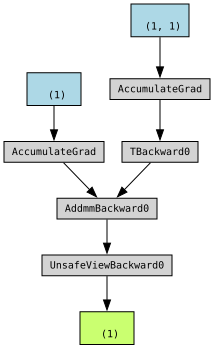

In [3]:
x = torch.tensor([1.0])
model = nn.Linear(1, 1)
print(model)
print(model.weight)
print(model.bias)
y=model(x)
print(y)
make_dot(y)

In [8]:
fc1 = nn.Linear(1, 3)
fc2 = nn.Linear(3, 1)
print(fc1.weight, fc1.weight.shape)  # w.shape=(out_features, in_features)
print(fc1.bias, fc1.bias.shape)
print(fc2.weight, fc2.bias)
x = torch.tensor([1.0])
x = fc1(x)
y = fc2(x)
print(x, y)
x = torch.tensor([1.0])
y2 = (x @ fc1.weight.T + fc1.bias) + fc2.weight
print(y2)

Parameter containing:
tensor([[-0.8694],
        [-0.4310],
        [ 0.9013]], requires_grad=True) torch.Size([3, 1])
Parameter containing:
tensor([-0.3488, -0.0846, -0.2951], requires_grad=True) torch.Size([3])
Parameter containing:
tensor([[0.4750, 0.1543, 0.1217]], requires_grad=True) Parameter containing:
tensor([-0.2191], requires_grad=True)
tensor([-1.2181, -0.5156,  0.6062], grad_fn=<UnsafeViewBackward0>) tensor([-0.8034], grad_fn=<UnsafeViewBackward0>)
tensor([[-0.7431, -0.3614,  0.7279]], grad_fn=<AddBackward0>)


feature과 channel의 차이
|구분|feature|channel|
|:---:|:---:|:---:|
|의미|데이터가 가진 특성 또는 변수|데이터의 독립적인 데이터 경로 또는 구성요소|
|예시|나이, 키, 몸무게|RGB 이미지의 R, G, B|
|주로 사용하는 곳|일반적인 데이터, 머신러닝, 완전연결층|이미지처리, CNN, 신호처리|

tensor([-0.9700,  0.4057])
tensor([1.0981, 0.1179, 0.1378], grad_fn=<UnsafeViewBackward0>)


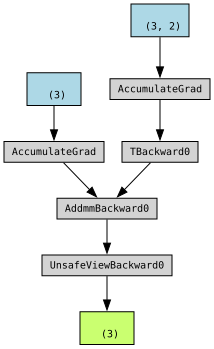

In [9]:
model = nn.Linear(2, 3)  # 2개의 채널을 가진 데이터를 3개의 채널을 가진 데이터로 변환
x = torch.randn(2)
print(x)
print(model(x))
make_dot(model(x))

In [13]:
model = nn.Linear(2, 3)
x = torch.randn(5, 2)  # 2개의 특징을 가지는 데이터 5개
print(x)
mx = model(x)
print(mx.shape)
x = torch.randn(4, 5, 2)
print(model(x).shape)
x = torch.randn(2, 3, 6, 5, 3, 2)
print(model(x).shape)

tensor([[ 1.4051,  0.1568],
        [ 1.1529, -0.4963],
        [-0.4394,  0.0711],
        [-0.5744, -0.2913],
        [ 0.9428,  0.1142]])
torch.Size([5, 3])
torch.Size([4, 5, 3])
torch.Size([2, 3, 6, 5, 3, 3])


In [14]:
fc1 = nn.Linear(1, 3)
fc2 = nn.Linear(3, 1)
x = torch.tensor([1.0])
x = fc1(x)
y = fc2(x)
model = nn.Sequential(fc1, fc2)
x = torch.tensor([1.0])
print(model(x))

tensor([0.4407], grad_fn=<UnsafeViewBackward0>)


In [15]:
model = nn.Sequential(nn.Linear(2, 5), nn.Linear(5, 10), nn.Linear(10, 3))
x = torch.randn(5, 2)
print(model(x))

tensor([[-0.0364, -0.2434, -0.0042],
        [ 0.1307, -0.0184, -0.1948],
        [ 0.0030,  0.2636,  0.2161],
        [ 0.1455, -0.2590, -0.3639],
        [-0.1355, -0.1855,  0.2206]], grad_fn=<AddmmBackward0>)


In [17]:
fc = nn.Linear(3, 2)
x = torch.tensor([[1.0, 2.0, 3.0], [2.0, 0.0, 1.0]])
fc.weight = nn.Parameter(torch.tensor([[1.0, 0.0, -1.0], [2.0, 1.0, 0.0]]))
fc.bias = nn.Parameter(torch.tensor([0.5, -1.0]))
y = fc(x)
print(fc.weight, fc.bias, x.shape, y.shape)

Parameter containing:
tensor([[ 1.,  0., -1.],
        [ 2.,  1.,  0.]], requires_grad=True) Parameter containing:
tensor([ 0.5000, -1.0000], requires_grad=True) torch.Size([2, 3]) torch.Size([2, 2])


In [20]:
m = nn.Sequential(
    nn.Linear(4, 6), nn.Sigmoid(), nn.Linear(6, 3), nn.Sigmoid(), nn.Linear(3, 2)
)
x = torch.randn(5, 4)
y = m(x)
print(x.shape, y.shape)
for a, b in m.named_modules():
    print(a, b)
    if isinstance(b, nn.Linear):
        print(b.weight.shape, b.bias.shape)

torch.Size([5, 4]) torch.Size([5, 2])
 Sequential(
  (0): Linear(in_features=4, out_features=6, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=6, out_features=3, bias=True)
  (3): Sigmoid()
  (4): Linear(in_features=3, out_features=2, bias=True)
)
0 Linear(in_features=4, out_features=6, bias=True)
torch.Size([6, 4]) torch.Size([6])
1 Sigmoid()
2 Linear(in_features=6, out_features=3, bias=True)
torch.Size([3, 6]) torch.Size([3])
3 Sigmoid()
4 Linear(in_features=3, out_features=2, bias=True)
torch.Size([2, 3]) torch.Size([2])


In [ ]:
x = torch.randn(2, 3, 5)
m = nn.Sequential(nn.Linear(5, 8), nn.relu(), nn.Linear(8, 2))
y = m(x)